## Exploring Stochastic Subspace Descent

In [218]:
import jax
import jax.numpy as jnp
from scipy import linalg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import line_search

### Algorithm: 
$$\vec{x}_{k+1} = \vec{x}_k + \alpha \textbf{P}_k \textbf{P}_k^T \nabla f(\vec{x_k})$$
$P \in R^{d \times l}, l \leq d$.  Note $0 < \alpha < 2 \textit{l}/(d\lambda)$

Haar Distributed random matrix: 
$$ \textbf{P} = \sqrt{d \textit{l}} \textbf{Q} \textbf{I}_{d \times l} \in \mathbb{R}^{d \times l}$$

Convergence rate:   
per Corollary 2.3 from 2019 ssd paper, convergence rate under strong convexity should be linear, where 
$$\mathbb{E} f(x_k) - f* \leq \beta^k (f(x_k) - f*), \quad \beta = 1 - l\gamma / d\lambda$$
where $\gamma$ is the smallest eigenvalue of A, and $\lambda$ is the lipschitz constant of the first derivative. 

Note from 5/15/2026 meeting: finding the $\lambda$ may not always be accessible for all functions. So we implement line search in the for-loop for each alpha, and that should yield better results than guessing. 

Think about what could change about the algorithm for nonlinear least squares function of the form
$$ f(\textbf{x} = \frac{1}{2} \sum_i r_i(\textbf{x})^2 = \frac{1}{2} ||r_i(\textbf{x})||^2$$
where $\nabla f = J^T \textbf{r}$

### Methodology
Need to: 
* define f such that it satisfies all assumptions outline in (D. Kozak et al.)
* define P
* iterative SSD algorithm with input f, P. Output parameters $\textbf{x}^*$ and plot loss function and convergence. 

Then compare results with other methods: 
- with line search: newton, BFGS(quasi-newton)
- without line search: block coordinate descent

### Objective Functions: 
Quadratic: strong convex
$$f(x) = \frac{1}{2} x^T A x - b^T x $$
* lambda is the spectral norm of A, so alpha can be determined
* gamma is the smallest eigenvalue of A, so beta can be determined
* exact solution can be determined using linalg.solve

Rosenbrock: non-convex
$$f(x) = \sum_{i=1}^{d-1} [100 (x_{i-1} - x_i^2)^2 + (x_i - 1)^2 ]$$
* 

[[ 4.81156532 -3.05140178  3.22482532  2.09100418]
 [-3.05140178  7.58120605 -0.34637347  1.1737824 ]
 [ 3.22482532 -0.34637347  3.18611924  2.00315997]
 [ 2.09100418  1.1737824   2.00315997  3.99612956]]
f (exact) = -6.6341684113469706
final f = -6.1763715744018555


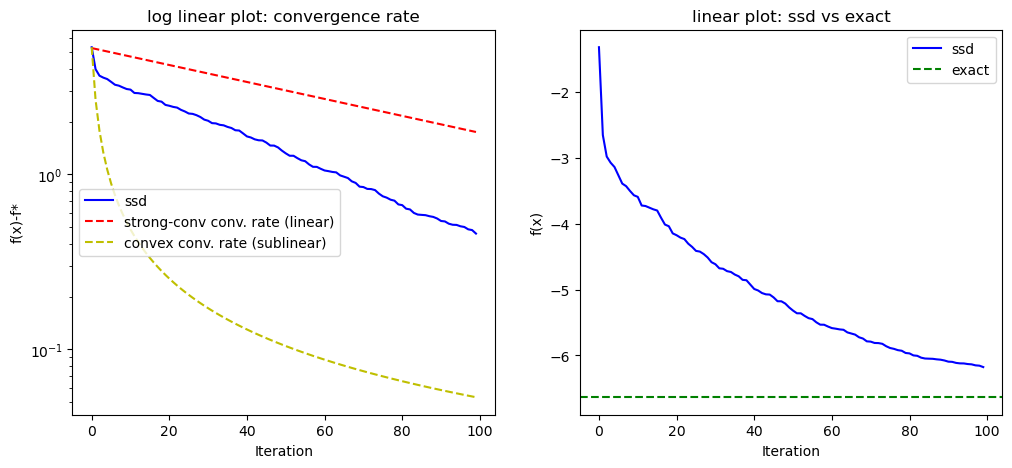

In [217]:
#input alpha and l, independent variables
#0 < alpha < 2l/(d*lambda). Why?

def ssd(x, alpha, l, f, max_iter=100, linesearch = False):
    '''
    followed algorithm 2.1:
    1: Inputs: α, l. step size, subspace rank
    2: Initialize: x0 . arbitrary initialization
    3: for k = 1, 2, . . . do
    4: Generate P_k
    5: Apply recursion
    '''
    
    d = x.shape[0]
    fx = []
    gradientFcn = jax.jit(jax.grad(f))
    for n in range(max_iter):
        #generate P using haar distribution (not necessary)
        Z = np.random.default_rng().standard_normal((d, l)) # 
        Q, R = linalg.qr(Z, mode='economic') #economic mode for finding the QR so it's not a full square matrix
        #lambda step is optional, only required for Haar. 
        # Lambda = np.diag(np.sign(np.diag(R))) # R_ii > 0, ensure unique QR fact. 
        P = np.sqrt(d / l) * Q 
        
        #recurse
        grad = gradientFcn(x)
        y = P.T @ grad
        step = P @ y
        if linesearch:
            alpha = line_search(
        else:
            x = x - alpha* step
        
        #plug x into function
        fx.append(float(f(jnp.array(x))))

    return fx


'''running the algorithm'''
l = 2    # intrinsic dimension (number of "important" directions)
key = jax.random.PRNGKey(0)
x = jax.random.uniform(key, shape=(d,))

# A random
A = np.random.randn(4,4)
A = A@A.T + 0.1 * np.eye(4)#A needs to be positive definite
print(A)
b = np.array([2, 4, 1, 3])

'''objective function'''
#convex function: x.T @ A @ x - b.T @ x.
f = lambda x: (0.5) * x.T @ A @ x - b.T @ x

# # #non-convex function: Rosenbrock. Need to look into non-convex function convergence. 
# f = lambda x: sum(100*(x[i+1] - x[i]**2)**2 + (1 - x[i])**2 
#                   for i in range(len(x)-1))

#alpha = l / (d*lam)
lam = linalg.norm(A, ord=2) #find spectral norm of A
alpha = l /(d*lam)
result = ssd(x, alpha, l, f)

#beta = 1 - (l*gamma) / (d*lambda)
gamma = np.min(linalg.eigvalsh(A))
beta = 1 - (l * gamma)/(d*lam)

#calculating the exact solution, then compare
# f_exact = quad(linalg.inv(A) @ b, A, b)
x_exact = linalg.solve(A,b, assume_a = 'pos')
f_exact = f(x_exact)
print("f (exact) =", f_exact)
print("final f =", result[-1])

#plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.set_title('log linear plot: convergence rate')
ax1.semilogy(result - f_exact, color='b', label='ssd')
initial_gap = result[0] - f_exact
k = np.arange(1, len(result) + 1)
ax1.semilogy(beta**k * initial_gap, color='r', ls='dashed', label='strong-conv conv. rate (linear)')
sublinear_rate = initial_gap / k
ax1.semilogy(sublinear_rate, color='y', ls='dashed', label='convex conv. rate (sublinear)')
ax1.set_xlabel("Iteration")
ax1.set_ylabel("f(x)-f*")
ax1.legend()

ax2.set_title('linear plot: ssd vs exact')
ax2.plot(result, color='b', label='ssd')
ax2.axhline(f_exact, color='g', label='exact', ls='dashed')
ax2.set_xlabel("Iteration")
ax2.set_ylabel("f(x)")
ax2.legend()

plt.show()

#### Outline the function for objective functions: 

considerations: 
- objective function defined as f, the lambda function.
- if a function has a known lambda, use it. Otherwise do line search on alpha. 
- if a function has a known solution, use it. Otherwise solve using scipy.linalg.solve
- find gamma.
- plot the convergence against strong convex, convex, and non-convex lines.
- build a class? yes

```
def eval(objective function, known lambda=false, f_exact=false, x, l, max_iter=)
    find alpha, lambda, beta, f_exact
    evaluate using ssd()
    plot
    return ?
```

In [ ]:
class Obj_func:
    def __init__(self, function):
        self.func

    

In [173]:
#newton's method w/o line search: alpha = 1
def newton(x0, f, max_iter=100, tol=1e-6):
    fx = []
    x = jnp.array(x0, dtype=float)
    for n in range(max_iter):
        grad = jax.grad(f)(x)

        #test tolerance
        if linalg.norm(grad) < tol:
            print (f" f (without line search) converged at iteration {n}")
            break

        H = jax.hessian(f)(x)
        p = linalg.solve(H, -grad)
        x = x + p
        fx.append(f(x))
    return fx

result_n = newton(np.random.rand(4).tolist(), f)

 f (without line search) converged at iteration 1


In [174]:
#newton's method with line search: 
def newton_ls(x0, f, max_iter=100, tol=1e-6):
    fx = []
    x = jnp.array(x0, dtype=float)
    grad_fn = lambda x: np.array(jax.grad(f)(jnp.array(x)))
    f_np = lambda x: float(f(jnp.array(x)))
    
    for n in range(max_iter):
        grad = jax.grad(f)(x)

        #test tolerance
        if linalg.norm(grad) < tol:
            print (f" f (with line search) converged at iteration {n}")
            break

        H = jax.hessian(f)(x)
        p = linalg.solve(H, -grad)

        #wolfe condition line search
        #scipy.optimize.line_search uses numpy array and functions. 
        alpha = line_search(f_np, grad_fn, np.array(x), np.array(p))
        
        x = x + alpha[0] * p
        fx.append(f(x))
    return fx

result_nls = newton_ls(np.random.rand(4).tolist(), f)

 f (with line search) converged at iteration 1


In [ ]:
#gradient descent
def grad_desc()